# M305 - Regresión y Clasificación

> Módulo IV - Machine Learning
>
> Tema 1: Algoritmos de aprendizaje supervisado (Clasificación/Regresión)

Contenido:

1. Espacio lineal
2. Modelo Lineal
3. Regresión
4. Modelo Logístico
5. Clasificación

Objetivo: Ajustar un modelo de regresión lineal en respuestas abiertas y un modelo de regresión logística en respuestas cerras

In [1]:
import numpy
import pandas

from matplotlib import pyplot
import seaborn

In [2]:
students = pandas.read_csv("./conjuntos/students.csv")

students

,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,screen_time,study_environment,access_to_tutoring,family_income_range,parental_support_level,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score
0,100000,26,Male,Computer Science,7.645367,3.0,0.1,Yes,70.3,6.2,...,10.9,Co-Learning Group,Yes,High,9,7,8,Reading,3.0,100
1,100001,28,Male,Arts,5.700000,0.5,0.4,No,88.4,7.2,...,8.3,Co-Learning Group,Yes,Low,7,2,10,Reading,6.0,99
2,100002,17,Male,Arts,2.400000,4.2,0.7,No,82.1,9.2,...,8.0,Library,Yes,High,3,9,6,Kinesthetic,7.6,98
3,100003,27,Other,Psychology,3.400000,4.6,2.3,Yes,79.3,4.2,...,11.7,Co-Learning Group,Yes,Low,5,3,10,Reading,3.2,100
4,100004,25,Female,Business,4.700000,0.8,2.7,Yes,62.9,6.5,...,9.4,Quiet Room,Yes,Medium,9,1,10,Reading,7.1,98
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79995,179995,16,Male,Engineering,3.700000,2.1,1.0,Yes,80.8,6.1,...,8.3,Library,No,Low,1,4,10,Auditory,5.3,88
79996,179996,16,Female,Business,1.200000,0.4,2.9,No,99.5,4.1,...,4.7,Co-Learning Group,No,Low,3,2,10,Kinesthetic,6.8,52
79997,179997,26,Female,Arts,4.100000,1.6,1.6,Yes,46.1,8.3,...,7.5,Dorm,No,Medium,7,1,10,Visual,1.3,89
79998,179998,23,Other,Biology,3.800000,0.6,3.5,Yes,58.7,5.8,...,9.3,Quiet Room,Yes,Low,2,8,7,Kinesthetic,3.7,96


In [3]:
x1 = students["study_hours_per_day"] # continua
x2 = students["social_media_hours"] # continua
x3 = students["netflix_hours"] # continua
x4 = students["sleep_hours"] # continua

y = students["exam_score"] # continua

<Axes: ylabel='Density'>

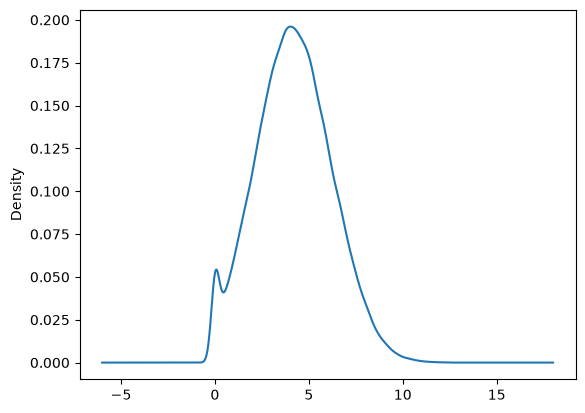

In [26]:
x1.plot.density()

<Axes: >

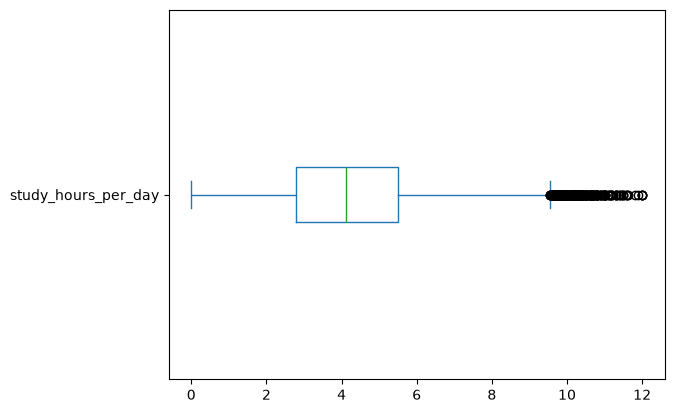

In [28]:
x1.plot.box(vert=False)

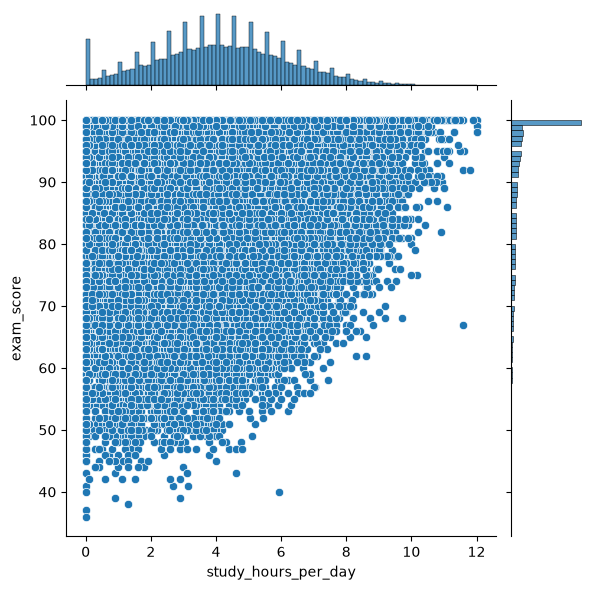

In [10]:
seaborn.jointplot(x=x1, y=y)

In [22]:
dx1 = pandas.qcut(x1, q=10)
dy = pandas.qcut(y, q=3)

M = pandas.DataFrame([dx1, dy]).T.groupby(["study_hours_per_day", "exam_score"]).size().unstack()

M

exam_score,"(35.999, 86.0]","(86.0, 98.0]","(98.0, 100.0]"
study_hours_per_day,,,
"(-0.001, 1.558]",4060,2379,1561
"(1.558, 2.408]",3495,2638,1867
"(2.408, 3.1]",3624,2923,2252
"(3.1, 3.6]",2750,2575,1989
"(3.6, 4.126]",2752,2838,2297
"(4.126, 4.7]",2950,3358,2843
"(4.7, 5.2]",2194,2699,2339
"(5.2, 5.9]",2252,3191,2862
"(5.9, 6.8]",1801,3074,2740


In [23]:
R1 = M.divide(M.sum(axis=1), axis=0)
R2 = M.divide(M.sum(axis=0), axis=1)

In [24]:
R1

exam_score,"(35.999, 86.0]","(86.0, 98.0]","(98.0, 100.0]"
study_hours_per_day,,,
"(-0.001, 1.558]",0.507500,0.297375,0.195125
"(1.558, 2.408]",0.436875,0.329750,0.233375
"(2.408, 3.1]",0.411865,0.332197,0.255938
"(3.1, 3.6]",0.375991,0.352065,0.271944
"(3.6, 4.126]",0.348929,0.359833,0.291239
"(4.126, 4.7]",0.322369,0.366954,0.310676
"(4.7, 5.2]",0.303374,0.373202,0.323424
"(5.2, 5.9]",0.271162,0.384226,0.344612
"(5.9, 6.8]",0.236507,0.403677,0.359816


In [25]:
R2

exam_score,"(35.999, 86.0]","(86.0, 98.0]","(98.0, 100.0]"
study_hours_per_day,,,
"(-0.001, 1.558]",0.149243,0.082541,0.065112
"(1.558, 2.408]",0.128474,0.091527,0.077876
"(2.408, 3.1]",0.133216,0.101416,0.093935
"(3.1, 3.6]",0.101088,0.089341,0.082965
"(3.6, 4.126]",0.101162,0.098466,0.095812
"(4.126, 4.7]",0.108440,0.116508,0.118587
"(4.7, 5.2]",0.080650,0.093644,0.097564
"(5.2, 5.9]",0.082782,0.110714,0.119379
"(5.9, 6.8]",0.066203,0.106655,0.114290


<Axes: xlabel='exam_score', ylabel='study_hours_per_day'>

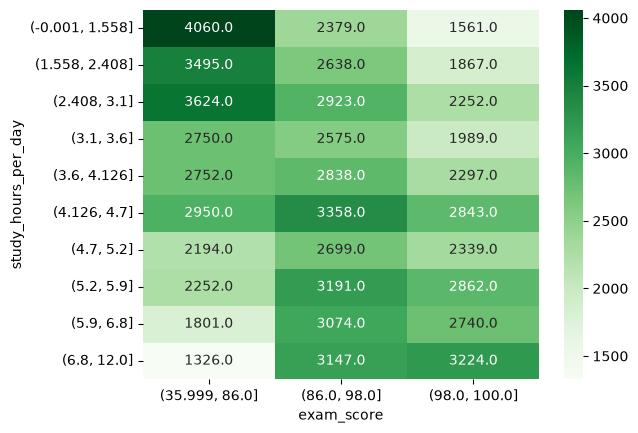

In [29]:
seaborn.heatmap(M, cmap="Greens", annot=True, fmt=".1f")

<Axes: xlabel='exam_score', ylabel='study_hours_per_day'>

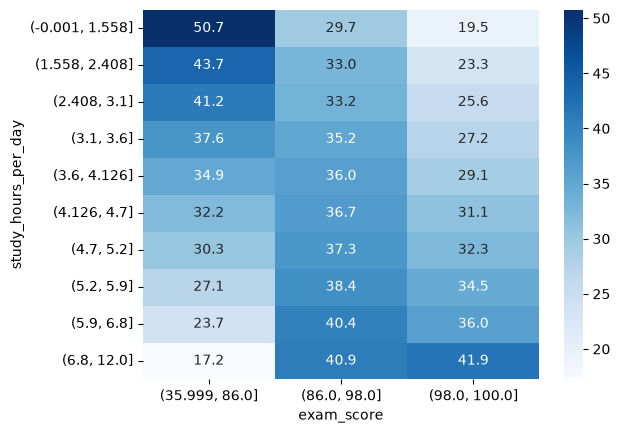

In [30]:
seaborn.heatmap(100 * R1, cmap="Blues", annot=True, fmt=".1f")

<Axes: xlabel='exam_score', ylabel='study_hours_per_day'>

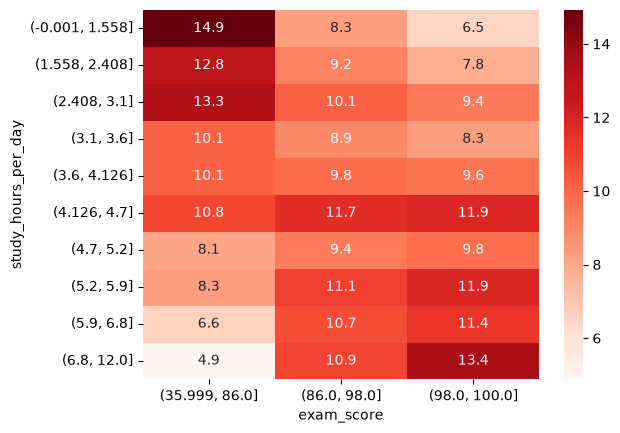

In [32]:
seaborn.heatmap(100 * R2, cmap="Reds", annot=True, fmt=".1f")

<Axes: xlabel='exam_score', ylabel='social_media_hours'>

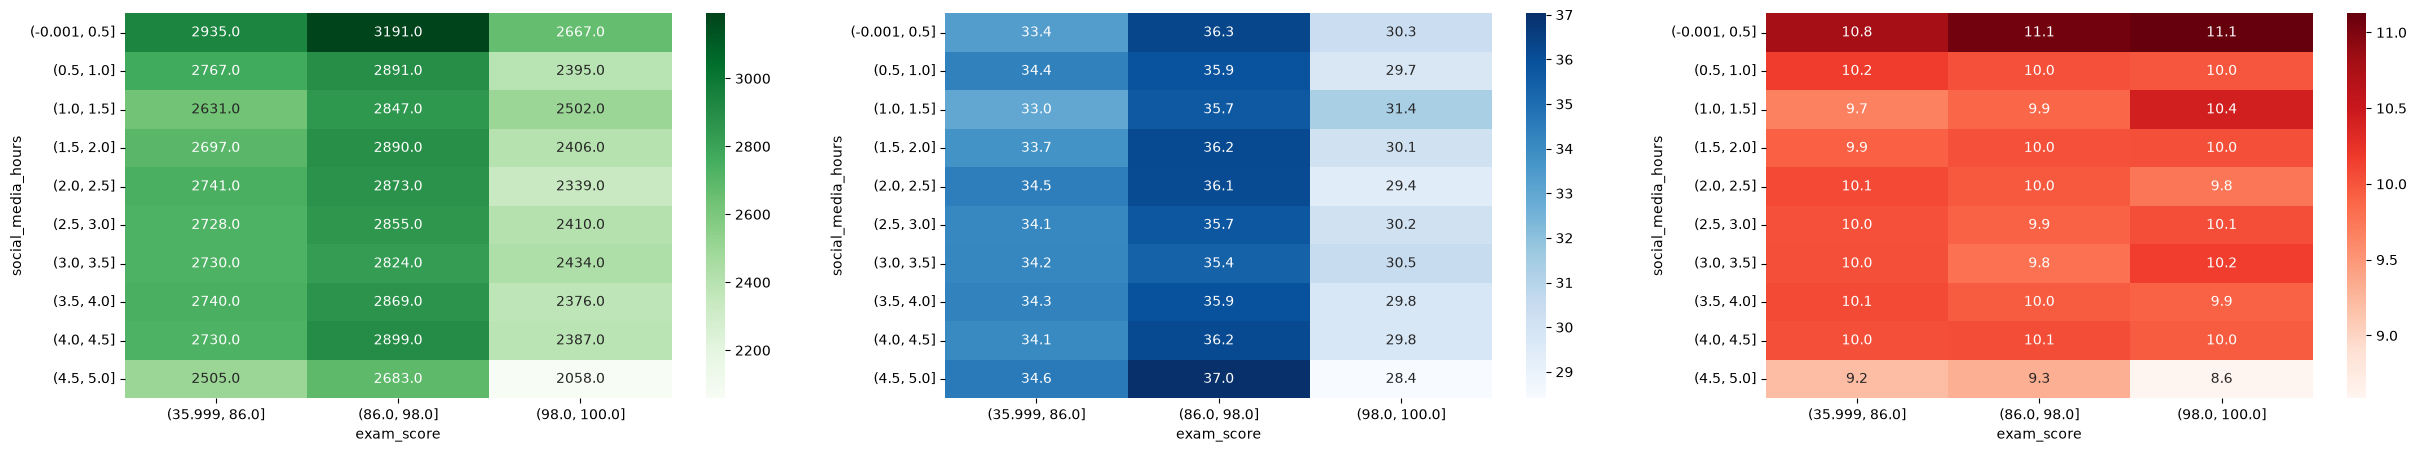

In [36]:
dx2 = pandas.qcut(x2, q=10)
dy = pandas.qcut(y, q=3)

M = pandas.DataFrame([dx2, dy]).T.groupby(["social_media_hours", "exam_score"]).size().unstack()
R1 = M.divide(M.sum(axis=1), axis=0)
R2 = M.divide(M.sum(axis=0), axis=1)

figure, axis = pyplot.subplots(1, 3, figsize=(30, 5))

seaborn.heatmap(M, cmap="Greens", annot=True, fmt=".1f", ax=axis[0])
seaborn.heatmap(100 * R1, cmap="Blues", annot=True, fmt=".1f", ax=axis[1])
seaborn.heatmap(100 * R2, cmap="Reds", annot=True, fmt=".1f", ax=axis[2])

<Axes: xlabel='exam_score', ylabel='netflix_hours'>

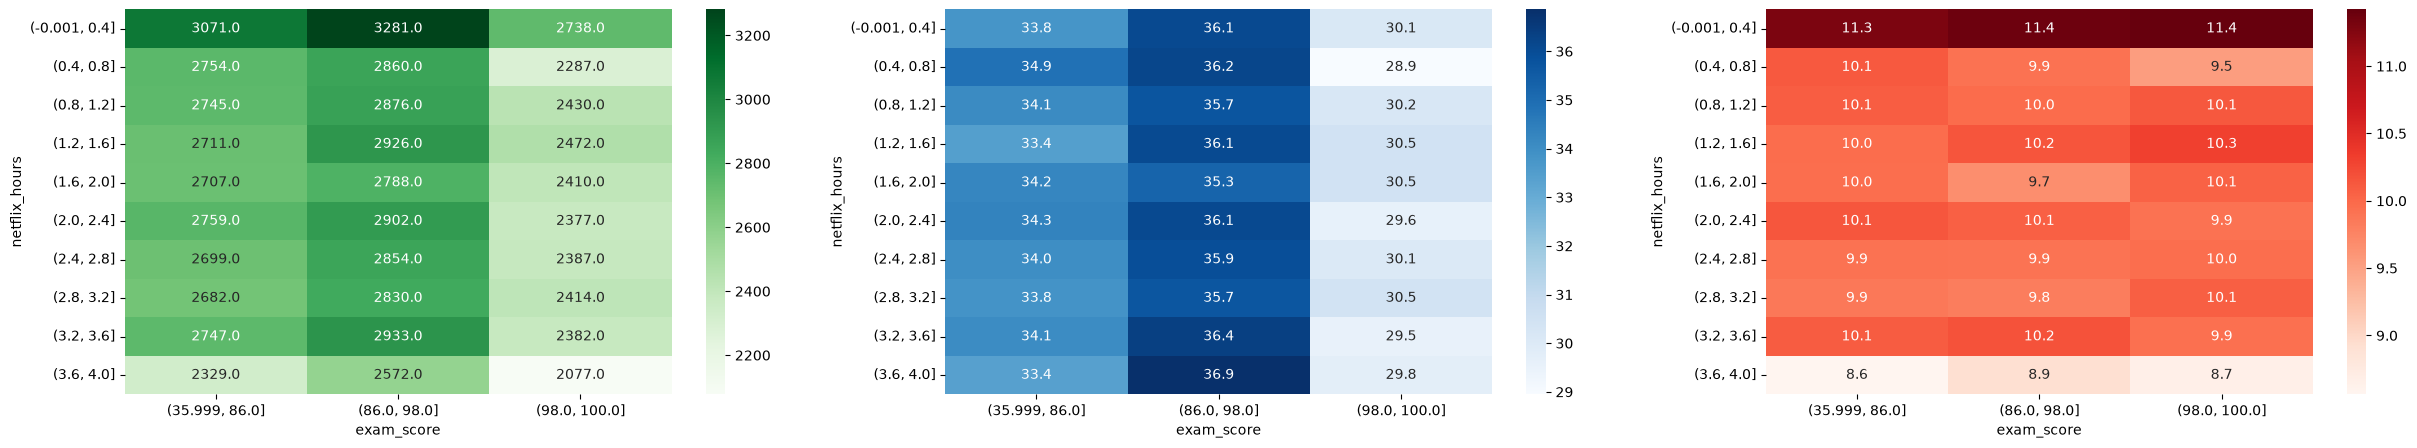

In [37]:
dx3 = pandas.qcut(x3, q=10)
dy = pandas.qcut(y, q=3)

M = pandas.DataFrame([dx3, dy]).T.groupby(["netflix_hours", "exam_score"]).size().unstack()
R1 = M.divide(M.sum(axis=1), axis=0)
R2 = M.divide(M.sum(axis=0), axis=1)

figure, axis = pyplot.subplots(1, 3, figsize=(30, 5))

seaborn.heatmap(M, cmap="Greens", annot=True, fmt=".1f", ax=axis[0])
seaborn.heatmap(100 * R1, cmap="Blues", annot=True, fmt=".1f", ax=axis[1])
seaborn.heatmap(100 * R2, cmap="Reds", annot=True, fmt=".1f", ax=axis[2])

<Axes: xlabel='exam_score', ylabel='sleep_hours'>

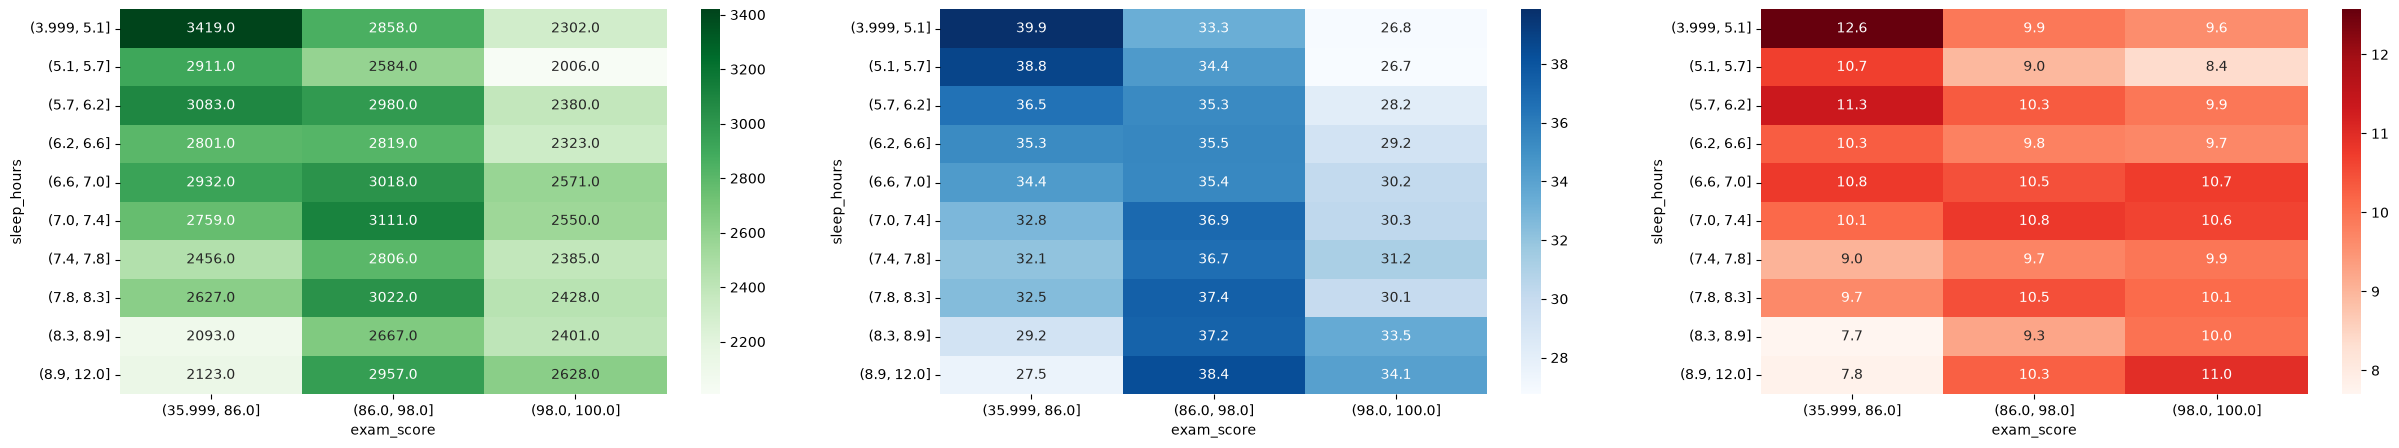

In [40]:
dx4 = pandas.qcut(x4, q=10)
dy = pandas.qcut(y, q=3)

M = pandas.DataFrame([dx4, dy]).T.groupby(["sleep_hours", "exam_score"]).size().unstack()
R1 = M.divide(M.sum(axis=1), axis=0)
R2 = M.divide(M.sum(axis=0), axis=1)

figure, axis = pyplot.subplots(1, 3, figsize=(30, 5))

seaborn.heatmap(M, cmap="Greens", annot=True, fmt=".1f", ax=axis[0])
seaborn.heatmap(100 * R1, cmap="Blues", annot=True, fmt=".1f", ax=axis[1])
seaborn.heatmap(100 * R2, cmap="Reds", annot=True, fmt=".1f", ax=axis[2])

Hipótesis:

* Las horas estudio impactan positivamente a la nota (entre más horas mejores notas)
* Las horas en redes sociales no impactan directamente a la nota (no se ve que cambien las probabilidades de sacar males, regulares o bunas notas)
* Las horas en netflix no impactan directamente a la nota (no se ve que cambien las probabilidades de sacar males, regulares o bunas notas)
* Las horas de sueño impactan positivamente a la nota (entre más horas mejores notas)

<Axes: xlabel='exam_score', ylabel='no_study_hours'>

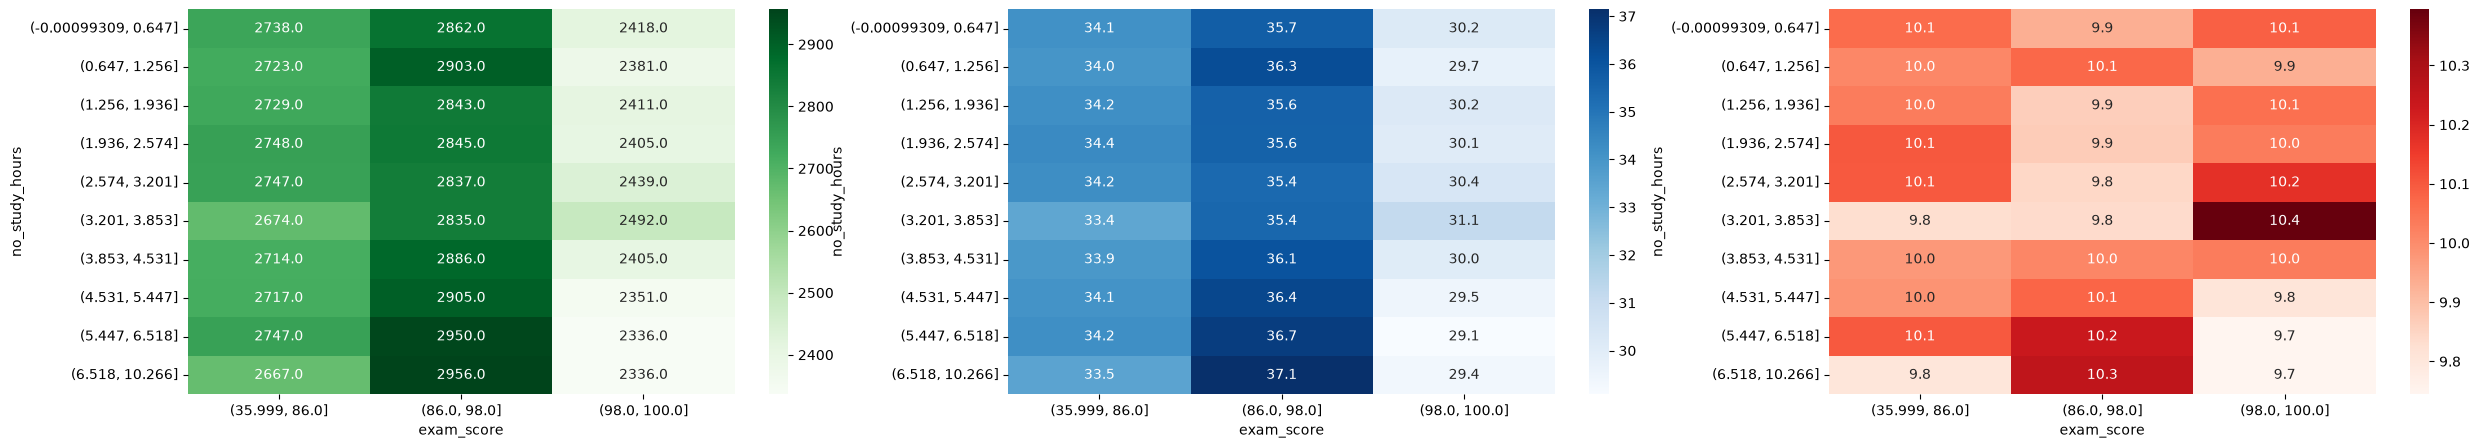

In [44]:
x5 = (x2 - x2.mean())**2 + (x3 - x3.mean())**2 # Métrica con normalización parcial
x5.name = "no_study_hours"

dx5 = pandas.qcut(x5, q=10)
dy = pandas.qcut(y, q=3)

M = pandas.DataFrame([dx5, dy]).T.groupby(["no_study_hours", "exam_score"]).size().unstack()
R1 = M.divide(M.sum(axis=1), axis=0)
R2 = M.divide(M.sum(axis=0), axis=1)

figure, axis = pyplot.subplots(1, 3, figsize=(30, 5))

seaborn.heatmap(M, cmap="Greens", annot=True, fmt=".1f", ax=axis[0])
seaborn.heatmap(100 * R1, cmap="Blues", annot=True, fmt=".1f", ax=axis[1])
seaborn.heatmap(100 * R2, cmap="Reds", annot=True, fmt=".1f", ax=axis[2])

## 1. Espacio lineal

In [45]:
x = pandas.Series([5, 8, 9, 10, 15, 24, 32], name="x")
y = pandas.Series([19, 27, 27, 30, 41, 60, 70], name="y")

pandas.DataFrame([x, y]).T

,x,y
0,5,19
1,8,27
2,9,27
3,10,30
4,15,41
5,24,60
6,32,70


<Axes: xlabel='x', ylabel='y'>

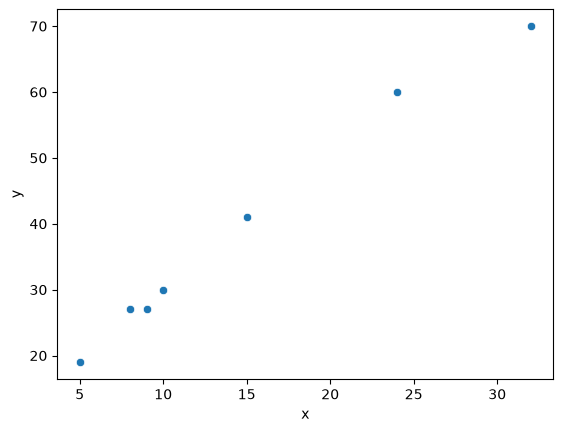

In [46]:
seaborn.scatterplot(x=x, y=y)

<Axes: xlabel='x', ylabel='y'>

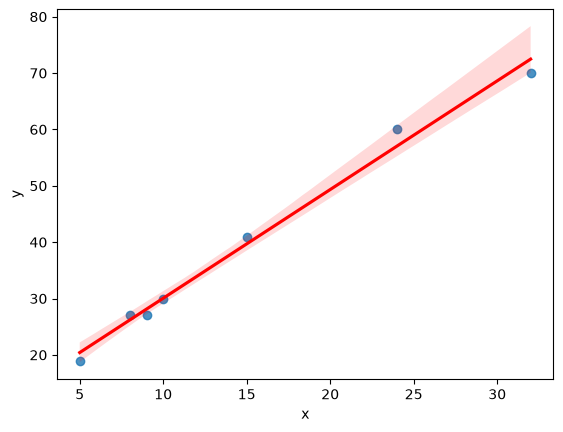

In [48]:
seaborn.regplot(x=x, y=y, line_kws={"color": "red"})

In [58]:
b0 = 6 # bias / interceptor
b1 = 0.5 # pendiente para x1

# Predictor lineal
z = b0 + b1 * x

# Modelo lineal: Yp(x, b) = Yp(z) = z
yp = z # Predicción sea lo que predice el predictor lineal
yp.name = "yp"

yp

0     8.5
1    10.0
2    10.5
3    11.0
4    13.5
5    18.0
6    22.0
Name: yp, dtype: float64

<Axes: xlabel='x', ylabel='y'>

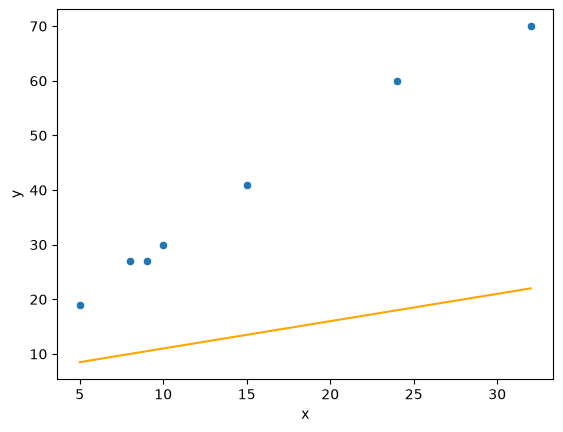

In [59]:
seaborn.scatterplot(x=x, y=y)
seaborn.lineplot(x=x, y=yp, color="orange")

<Axes: xlabel='x', ylabel='y'>

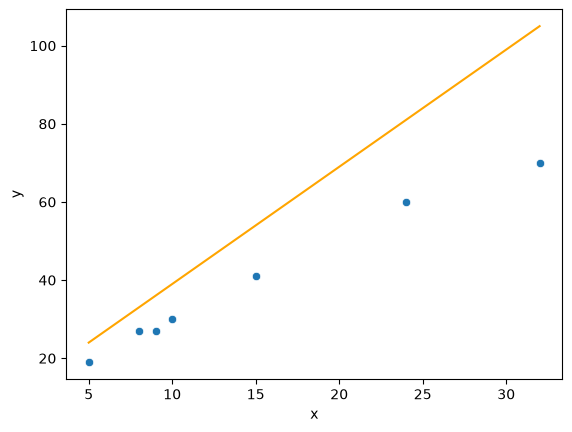

In [87]:
b0 = 9 # bias / interceptor
b1 = 3 # pendiente para x1

# Predictor lineal
z = b0 + b1 * x

# Modelo lineal: Yp(x, b) = Yp(z) = z
yp = z # Predicción sea lo que predice el predictor lineal
yp.name = "yp"

seaborn.scatterplot(x=x, y=y)
seaborn.lineplot(x=x, y=yp, color="orange")

In [88]:
pandas.DataFrame([x, y, yp]).T

,x,y,yp
0,5,19,24
1,8,27,33
2,9,27,36
3,10,30,39
4,15,41,54
5,24,60,81
6,32,70,105


In [89]:
e = y - yp
e.name = "error"

pandas.DataFrame([x, y, yp, e]).T

,x,y,yp,error
0,5,19,24,-5
1,8,27,33,-6
2,9,27,36,-9
3,10,30,39,-9
4,15,41,54,-13
5,24,60,81,-21
6,32,70,105,-35


<Axes: ylabel='Density'>

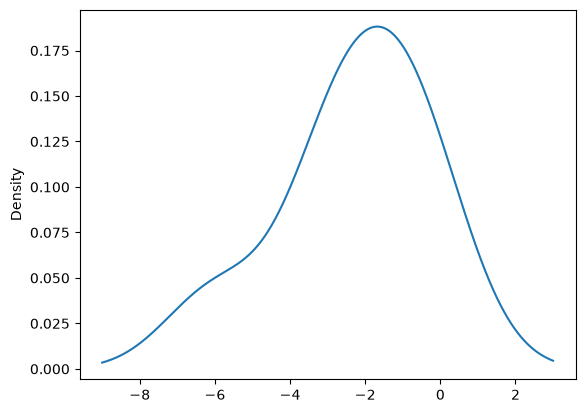

In [84]:
e.plot.density()

In [90]:
l = (e ** 2).mean()

l

np.float64(294.0)

## 2. Modelo Lineal

$$
x \in \mathbb{R}, y \in \mathbb{R}
$$

$$
\beta \in \mathbb{R}^2
$$

$$
\beta = (\beta_0, \beta_1)
$$

$$
z = \beta_0 + \beta_1 \cdot x
$$

$$
\hat{y} = \phi(x, \beta) = \phi(z) = z
$$

$$
\hat{y}(x^{(1)}) \approx y^{(1)}
$$
$$
\hat{y}(x^{(2)}) \approx y^{(2)}
$$
...
$$
\hat{y}(x^{(n)}) \approx y^{(n)}
$$

$$
\varepsilon^{(1)} = y^{(1)} - \hat{y}(x^{(1)})
$$
$$
\varepsilon^{(2)} = y^{(2)} - \hat{y}(x^{(2)})
$$
...
$$
\varepsilon^{(n)} = y^{(n)} - \hat{y}(x^{(n)})
$$

$$
L = \frac{1}{n} \sum_{i = 1}^{n} (\varepsilon^{(i)})^2
$$

In [91]:
def lineal(x, b0, b1):
    return b0 + b1 * x

def model(z):
    return z

def error(y, yp):
    return y - yp

def mse(e):
    return (e ** 2).mean()

def loss(e):
    return mse(e)

In [93]:
x = pandas.Series([5, 8, 9, 10, 15, 24, 32], name="x")
y = pandas.Series([19, 27, 27, 30, 41, 60, 70], name="y")

In [94]:
b0 = 1
b1 = 1

In [96]:
loss(error(y, model(lineal(x, b0, b1))))

np.float64(623.1428571428571)

In [97]:
b0 = 1
b1 = 2

loss(error(y, model(lineal(x, b0, b1))))

np.float64(79.28571428571429)

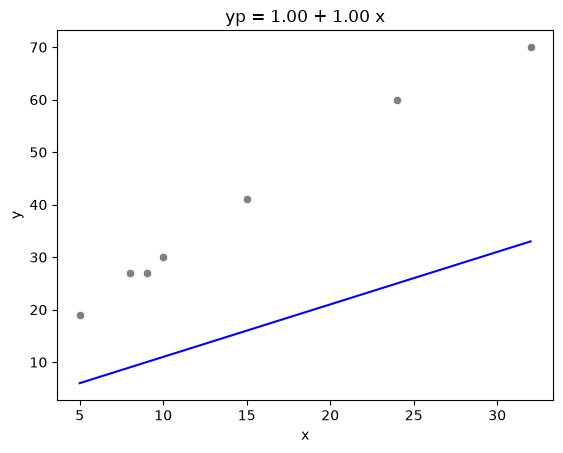

Época 1 | b0=  1.00, b1=  1.00 (623.14) | b0a=  2.06, b1a=  1.61 (192.25)


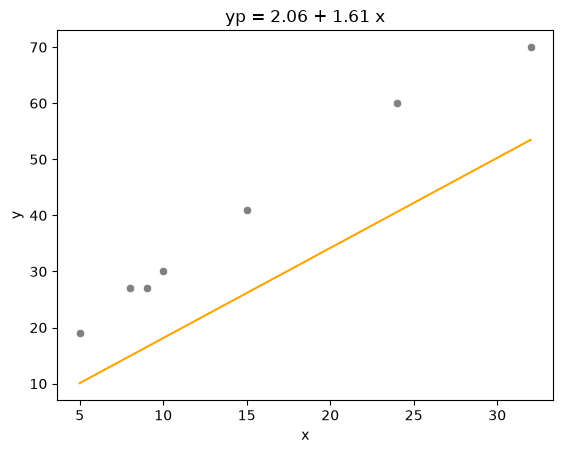

Época 4 | b0=  2.06, b1=  1.61 (192.25) | b0a=  1.19, b1a=  2.23 ( 36.65)


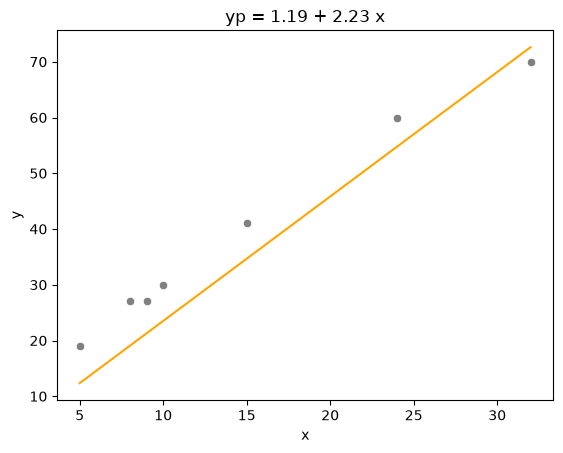

Época 6 | b0=  1.19, b1=  2.23 ( 36.65) | b0a=  2.47, b1a=  2.19 ( 28.32)


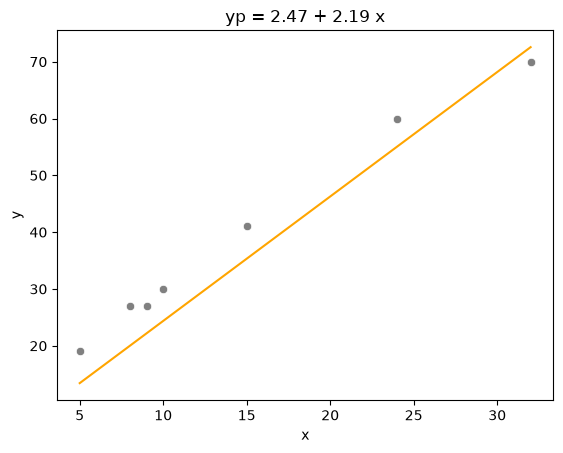

Época 22 | b0=  2.47, b1=  2.19 ( 28.32) | b0a=  2.28, b1a=  2.36 ( 22.90)


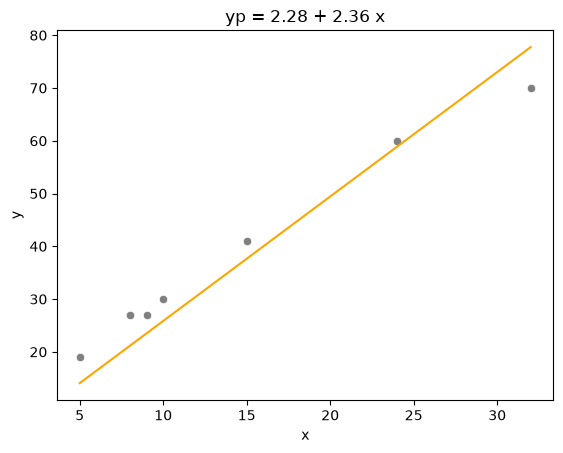

Época 37 | b0=  2.28, b1=  2.36 ( 22.90) | b0a=  3.52, b1a=  2.42 ( 22.87)


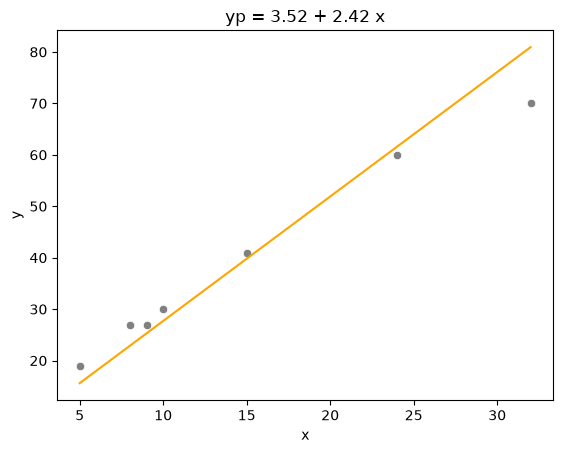

Época 48 | b0=  3.52, b1=  2.42 ( 22.87) | b0a=  3.75, b1a=  2.36 ( 18.70)


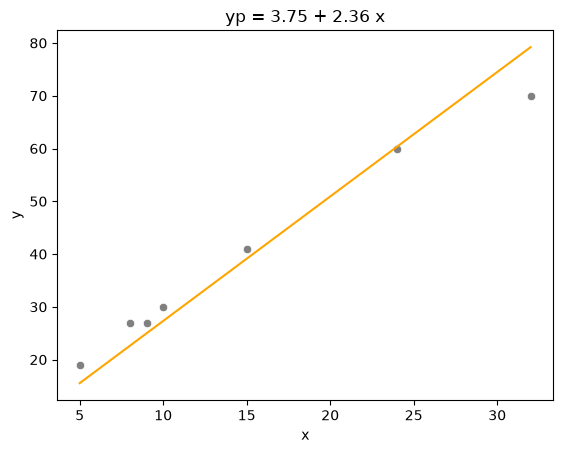

Época 51 | b0=  3.75, b1=  2.36 ( 18.70) | b0a=  4.52, b1a=  2.28 ( 14.20)


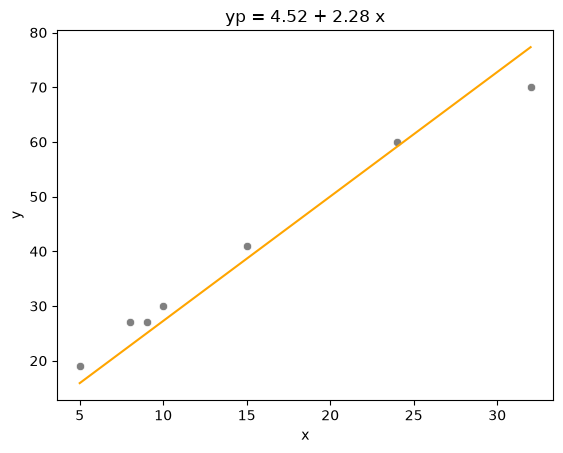

Época 54 | b0=  4.52, b1=  2.28 ( 14.20) | b0a=  4.76, b1a=  2.16 ( 14.18)


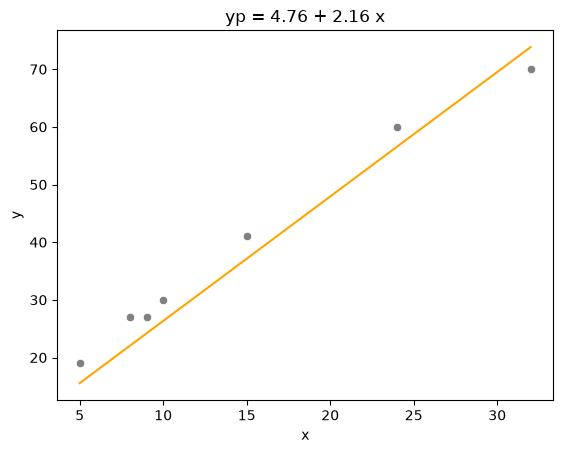

Época 63 | b0=  4.76, b1=  2.16 ( 14.18) | b0a=  6.48, b1a=  2.03 ( 11.55)


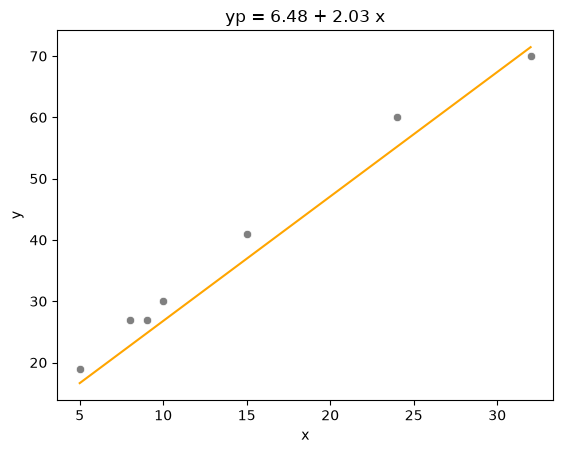

Época 79 | b0=  6.48, b1=  2.03 ( 11.55) | b0a=  7.21, b1a=  2.14 (  6.73)


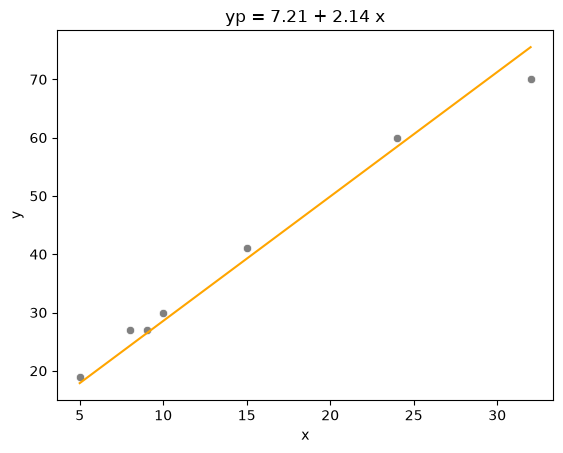

Época 182 | b0=  7.21, b1=  2.14 (  6.73) | b0a=  9.18, b1a=  1.97 (  4.11)


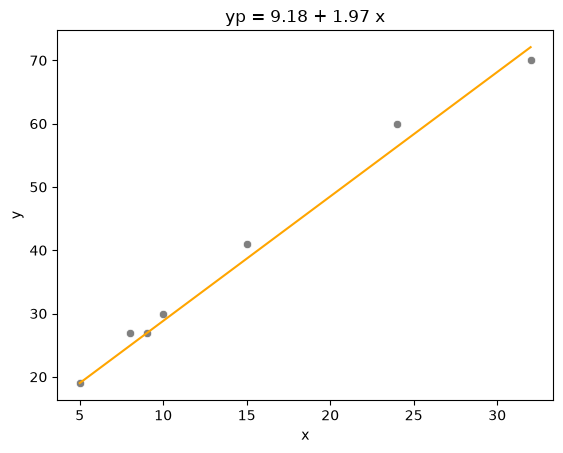

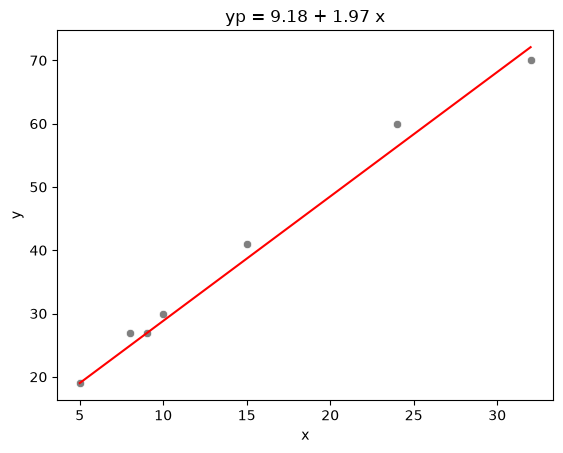

In [109]:
b0 = 1 # inicial
b1 = 1 # inicial

pyplot.clf()
seaborn.scatterplot(x=x, y=y, color="gray")
seaborn.lineplot(x=x, y=model(lineal(x, b0, b1)), color="blue")
pyplot.title(f"yp = {b0:.2f} + {b1:.2f} x")
pyplot.show()

for epoca in range(200):
    l = loss(error(y, model(lineal(x, b0, b1))))

    b0a = numpy.random.normal(b0, 1)
    b1a = numpy.random.normal(b1, 1)

    la = loss(error(y, model(lineal(x, b0a, b1a))))

    if l > la:
        print(f"Época {epoca} | b0={b0:6.2f}, b1={b1:6.2f} ({l:6.2f}) | b0a={b0a:6.2f}, b1a={b1a:6.2f} ({la:6.2f})")
        b0 = b0a
        b1 = b1a
        
        pyplot.clf()
        seaborn.scatterplot(x=x, y=y, color="gray")
        seaborn.lineplot(x=x, y=model(lineal(x, b0, b1)), color="orange")
        pyplot.title(f"yp = {b0:.2f} + {b1:.2f} x")
        pyplot.show()

pyplot.clf()
seaborn.scatterplot(x=x, y=y, color="gray")
seaborn.lineplot(x=x, y=model(lineal(x, b0, b1)), color="red")
pyplot.title(f"yp = {b0:.2f} + {b1:.2f} x")
pyplot.show()

In [113]:
b0 = 1 # inicial
b1 = 1 # inicial

for epoca in range(10_000):
    l = loss(error(y, model(lineal(x, b0, b1))))

    b0a = numpy.random.normal(b0, 1)
    b1a = numpy.random.normal(b1, 1)

    la = loss(error(y, model(lineal(x, b0a, b1a))))

    if l > la:
        b0 = b0a
        b1 = b1a

b0, b1

(10.855019519333245, 1.923884745533325)

In [111]:
from scipy.stats import linregress

linregress(x, y)

LinregressResult(slope=np.float64(1.9282544378698223), intercept=np.float64(10.76997041420119), rvalue=np.float64(0.995288360241812), pvalue=np.float64(2.9193552925334406e-06), stderr=np.float64(0.08400773698170341), intercept_stderr=np.float64(1.4533234441636025))

In [114]:
result = linregress(x, y)

result.intercept, result.slope

(np.float64(10.76997041420119), np.float64(1.9282544378698223))

## 3. Regresión

In [118]:
x1 = students["study_hours_per_day"]
x2 = students["sleep_hours"]

y = students["exam_score"]

pandas.DataFrame([x1, x2, y]).T

,study_hours_per_day,sleep_hours,exam_score
0,7.645367,6.2,100.0
1,5.700000,7.2,99.0
2,2.400000,9.2,98.0
3,3.400000,4.2,100.0
4,4.700000,6.5,98.0
...,...,...,...
79995,3.700000,6.1,88.0
79996,1.200000,4.1,52.0
79997,4.100000,8.3,89.0
79998,3.800000,5.8,96.0


### Modelo de Regresión Lineal Múltiple

$$
z = \beta_0 + \beta_1 \cdot x_1 + \beta_2 \cdot x_2
$$

$$
\hat{y} = z
$$

In [119]:
def lineal(x, betas):
    return betas[0] + x.dot(betas[1:])

def model(z):
    return z

def error(y, yp):
    return y - yp

def mse(e):
    return (e ** 2).mean()

def loss(e):
    return mse(e)

In [124]:
# Recta: y = m x + b
# Plano: y = a x1 + b x2 + c

# yp = b0 + b1 x1 + b2 x2

betas = numpy.array([1, 1, 1]) # (b0, b1, b2)

x = pandas.DataFrame([x1, x2]).T.values

array([[7.64536653, 6.2       ],
       [5.7       , 7.2       ],
       [2.4       , 9.2       ],
       ...,
       [4.1       , 8.3       ],
       [3.8       , 5.8       ],
       [3.        , 5.3       ]], shape=(80000, 2))

In [130]:
betas = numpy.array([1, 1, 1]) # (b0, b1, b2)

print(betas)

for epoca in range(100):
    l = loss(error(y, model(lineal(x, betas))))

    betas_a = betas + numpy.random.normal(0, 1, betas.size)

    la = loss(error(y, model(lineal(x, betas_a))))

    if l > la:
        print(f"Época {epoca}: {betas.round(1)} ({l:.2f}) | {betas_a.round(1)} ({la:.2f})")
        betas = betas_a

betas

[1 1 1]
Época 2: [1 1 1] (6047.45) | [0.4 0.1 2.8] (4850.33)
Época 4: [0.4 0.1 2.8] (4850.33) | [ 0.4 -0.8  3.8] (4396.68)
Época 6: [ 0.4 -0.8  3.8] (4396.68) | [ 0.6 -0.2  4.1] (3829.20)
Época 8: [ 0.6 -0.2  4.1] (3829.20) | [ 0.1 -0.6  5.1] (3270.49)
Época 9: [ 0.1 -0.6  5.1] (3270.49) | [ 0.6 -1.   6.7] (2340.90)
Época 11: [ 0.6 -1.   6.7] (2340.90) | [0.1 0.1 7.7] (1402.72)
Época 13: [0.1 0.1 7.7] (1402.72) | [0.1 0.2 9.6] (738.14)
Época 16: [0.1 0.2 9.6] (738.14) | [0.5 0.9 9.8] (570.65)
Época 17: [0.5 0.9 9.8] (570.65) | [ 0.9  1.7 10.1] (424.37)
Época 18: [ 0.9  1.7 10.1] (424.37) | [-0.4  2.7  9.8] (402.93)
Época 19: [-0.4  2.7  9.8] (402.93) | [ 0.   2.6 10.6] (356.58)
Época 34: [ 0.   2.6 10.6] (356.58) | [0.5 3.6 9.9] (344.29)
Época 48: [0.5 3.6 9.9] (344.29) | [ 0.1  3.9 10.1] (344.01)
Época 50: [ 0.1  3.9 10.1] (344.01) | [1.2 3.6 9.8] (339.87)
Época 60: [1.2 3.6 9.8] (339.87) | [2.1 4.1 9.8] (332.84)
Época 90: [2.1 4.1 9.8] (332.84) | [3.2 4.5 9.3] (325.50)


array([3.23787774, 4.45743778, 9.26967194])

In [133]:
b0 = 3.23787774
b1 = 4.45743778
b2 = 9.26967194

yp = b0 + b1 * x1 + b2 * x2
yp.name = "yp"

pandas.DataFrame([x1, x2, y, yp]).T

,study_hours_per_day,sleep_hours,exam_score,yp
0,7.645367,6.2,100.0,94.788589
1,5.700000,7.2,99.0,95.386911
2,2.400000,9.2,98.0,99.216710
3,3.400000,4.2,100.0,57.325788
4,4.700000,6.5,98.0,84.440703
...,...,...,...,...
79995,3.700000,6.1,88.0,76.275396
79996,1.200000,4.1,52.0,46.592458
79997,4.100000,8.3,89.0,98.451650
79998,3.800000,5.8,96.0,73.940239


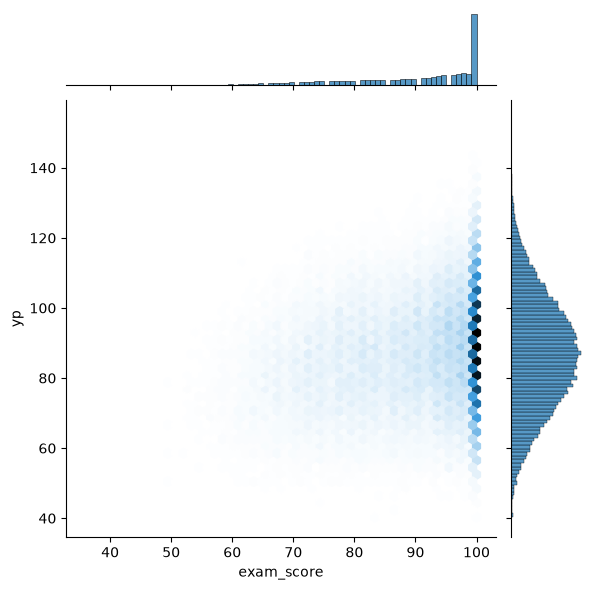

In [142]:
seaborn.jointplot(x=y, y=yp, kind="hex")

<Axes: ylabel='Density'>

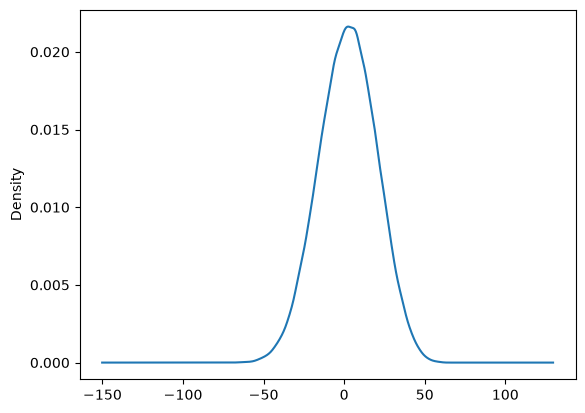

In [135]:
e = y - yp

e.plot.density()

In [137]:
# MAE - Mean Absolute Error

e.abs().mean()

np.float64(14.538502385589616)

In [140]:
result = linregress(x1, y)

b0 = result.intercept
b1 = result.slope

yp1 = b0 + b1 * x1

pandas.DataFrame([x1, y, yp1]).T

,study_hours_per_day,exam_score,study_hours_per_day
0,7.645367,100.0,93.988764
1,5.700000,99.0,91.271952
2,2.400000,98.0,86.663318
3,3.400000,100.0,88.059874
4,4.700000,98.0,89.875396
...,...,...,...
79995,3.700000,88.0,88.478841
79996,1.200000,52.0,84.987452
79997,4.100000,89.0,89.037463
79998,3.800000,96.0,88.618496


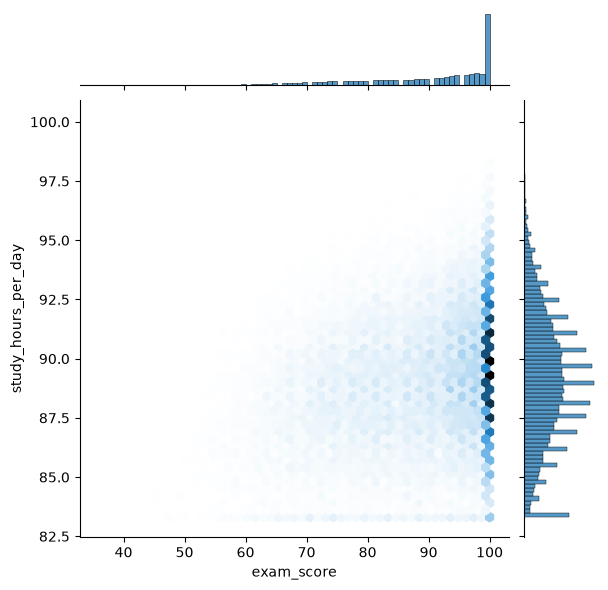

In [143]:
seaborn.jointplot(x=y, y=yp1, kind="hex")

<Axes: ylabel='Density'>

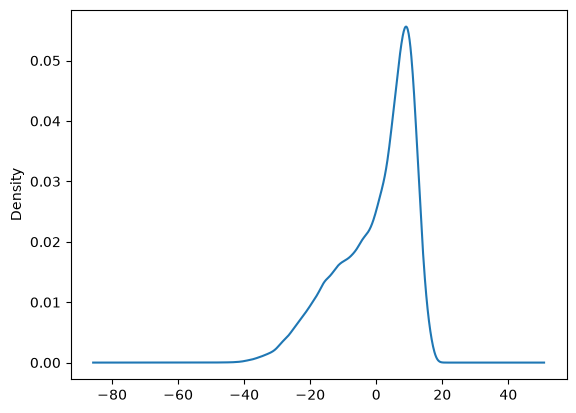

In [144]:
e1 = y - yp1

e1.plot.density()

In [145]:
e1.abs().mean()

np.float64(9.273553402879443)

In [150]:
result = linregress(x2, y)

b0 = result.intercept
b1 = result.slope

yp2 = b0 + b1 * x2

pandas.DataFrame([x2, y, yp2]).T

,sleep_hours,exam_score,sleep_hours
0,6.2,100.0,88.554908
1,7.2,99.0,89.272341
2,9.2,98.0,90.707205
3,4.2,100.0,87.120044
4,6.5,98.0,88.770138
...,...,...,...
79995,6.1,88.0,88.483165
79996,4.1,52.0,87.048301
79997,8.3,89.0,90.061516
79998,5.8,96.0,88.267935


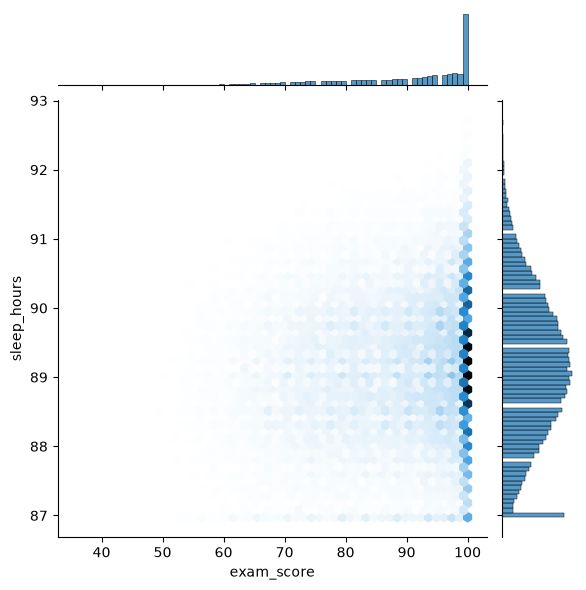

In [151]:
seaborn.jointplot(x=y, y=yp2, kind="hex")

<Axes: ylabel='Density'>

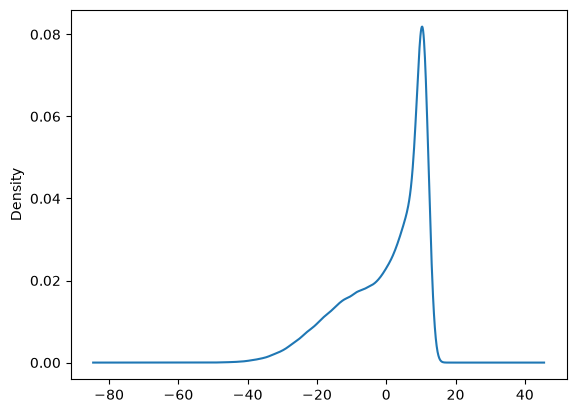

In [152]:
e2 = y - yp2

e2.plot.density()

In [153]:
e2.abs().mean()

np.float64(9.572845203025624)

### Regresión Lineal

In [154]:
x1 = students["study_hours_per_day"] # continua
x2 = students["social_media_hours"] # continua
x3 = students["netflix_hours"] # continua
x4 = students["sleep_hours"] # continua

y = students["exam_score"] # continua

In [156]:
X = pandas.DataFrame([x1, x2, x3, x4]).T

X

,study_hours_per_day,social_media_hours,netflix_hours,sleep_hours
0,7.645367,3.0,0.1,6.2
1,5.700000,0.5,0.4,7.2
2,2.400000,4.2,0.7,9.2
3,3.400000,4.6,2.3,4.2
4,4.700000,0.8,2.7,6.5
...,...,...,...,...
79995,3.700000,2.1,1.0,6.1
79996,1.200000,0.4,2.9,4.1
79997,4.100000,1.6,1.6,8.3
79998,3.800000,0.6,3.5,5.8


In [161]:
# ! python -m pip install scikit-learn

In [163]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X, y)

model

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 1.4 ,-0.05,-0.01, 0.72]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['study_hours_per_day','social_media_hours','netflix_hours','sleep_hours']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,78.4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [167]:
# yp = 78.4 + 1.4 x1 - 0.05 x2 - 0.01 x3 + 0.72 x4

# yp = 78.4 + 1.4 * x1 - 0.05 * x2 - 0.01 * x3 + 0.72 * x4
yp = model.predict(X)

pandas.DataFrame([x1, x2, x3, x4, y, yp]).T

,study_hours_per_day,social_media_hours,netflix_hours,sleep_hours,exam_score,Unnamed 0
0,7.645367,3.0,0.1,6.2,100.0,93.390155
1,5.700000,0.5,0.4,7.2,99.0,91.503799
2,2.400000,4.2,0.7,9.2,98.0,88.159621
3,3.400000,4.6,2.3,4.2,100.0,85.939254
4,4.700000,0.8,2.7,6.5,98.0,89.577914
...,...,...,...,...,...,...
79995,3.700000,2.1,1.0,6.1,88.0,87.844091
79996,1.200000,0.4,2.9,4.1,52.0,82.983638
79997,4.100000,1.6,1.6,8.3,89.0,90.001775
79998,3.800000,0.6,3.5,5.8,96.0,87.823001


In [168]:
(y - yp).abs().mean()

np.float64(9.223251763002164)

## 4. Modelo Logístico

## 5. Clasificación